# SVM — MNIST: 3 ou 6

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

In [ ]:
mnist = fetch_openml("mnist_784", version=1)
rotulos = mnist.target.astype(int).to_numpy()
indices = np.flatnonzero(np.isin(rotulos[:60000], [3, 6]))
indices_treino, _ = train_test_split(
    indices, train_size=300, stratify=rotulos[indices], random_state=42
)
indices_teste = np.flatnonzero(np.isin(rotulos[60000:], [3, 6])) + 60000

X_treino = mnist.data.iloc[indices_treino].to_numpy(dtype=float) / 255
X_teste = mnist.data.iloc[indices_teste].to_numpy(dtype=float) / 255
y_treino = rotulos[indices_treino]
y_teste = rotulos[indices_teste]

imagens_teste = X_teste.reshape(-1, 28, 28)
pca = PCA(n_components=2, random_state=42)
scaler = StandardScaler()
X_treino = scaler.fit_transform(pca.fit_transform(X_treino))
X_teste = scaler.transform(pca.transform(X_teste))

/home/gabriel/Documents/Projects/qc_minicurso/.env/lib/python3.14/site-packages/sklearn/datasets/_openml.py:95: RuntimeWarning: Invalid cache, redownloading file to /home/gabriel/scikit_learn_data/openml/openml.org/data/v1/download/52667/mnist_784.arff.gz
  warn(


In [ ]:
def mostrar_digitos(previsoes=None):
    indices = np.concatenate([np.flatnonzero(y_teste == digito)[:6] for digito in [3, 6]])
    fig, eixos = plt.subplots(2, 6, figsize=(10, 4))
    for eixo, indice in zip(eixos.flat, indices):
        eixo.imshow(imagens_teste[indice], cmap="gray_r")
        titulo = f"Real: {y_teste[indice]}"
        if previsoes is not None:
            titulo += f" | SVM: {previsoes[indice]}"
        eixo.set_title(titulo, fontsize=9)
        eixo.axis("off")
    plt.tight_layout()
    plt.show()


def plotar_svm(modelo):
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
    for eixo in eixos:
        for digito, cor in [(3, "tab:blue"), (6, "tab:orange")]:
            filtro = y_treino == digito
            eixo.scatter(X_plot[filtro, 0], X_plot[filtro, 1], color=cor, label=str(digito), s=25)
        eixo.set_xlim(x_min, x_max)
        eixo.set_ylim(y_min, y_max)
        eixo.set_xlabel("Componente 1 padronizada")
        eixo.set_ylabel("Componente 2 padronizada")
    eixos[0].set_title("Dados projetados")
    eixos[1].set_title("Dados com a solução do SVM")
    pesos = modelo.coef_[0]
    valores = pesos[0] * xx + pesos[1] * yy + modelo.intercept_[0]
    eixos[1].contour(
        xx, yy, valores, levels=[-1, 0, 1], colors="black",
        linestyles=["--", "-", "--"],
    )
    suporte = modelo.support_
    eixos[1].scatter(
        X_plot[suporte, 0], X_plot[suporte, 1], s=85, facecolors="none",
        edgecolors="black", label="Vetores de suporte",
    )
    for eixo in eixos:
        eixo.legend()
    plt.tight_layout()
    plt.show()


def mostrar_resultados(modelo):
    previsoes = modelo.predict(X_teste)
    mostrar_digitos(previsoes)
    display(pd.DataFrame(
        confusion_matrix(y_teste, previsoes, labels=[3, 6]),
        index=pd.Index([3, 6], name="Real"),
        columns=pd.Index([3, 6], name="Previsto"),
    ))

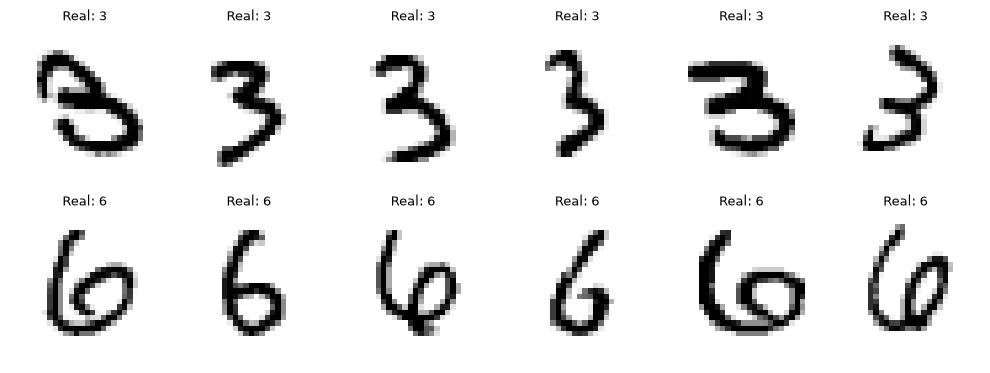

In [ ]:
mostrar_digitos()

In [ ]:
svm_rigido = SVC(kernel="linear", C=1000, tol=1e-4).fit(X_treino, y_treino)
svm_suave  = SVC(kernel="linear", C=0.1, tol=1e-4).fit(X_treino, y_treino)

X_plot = X_treino
x_min, y_min = X_plot.min(axis=0) - 0.5
x_max, y_max = X_plot.max(axis=0) + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

## Margem rígida (aproximação com C alto)

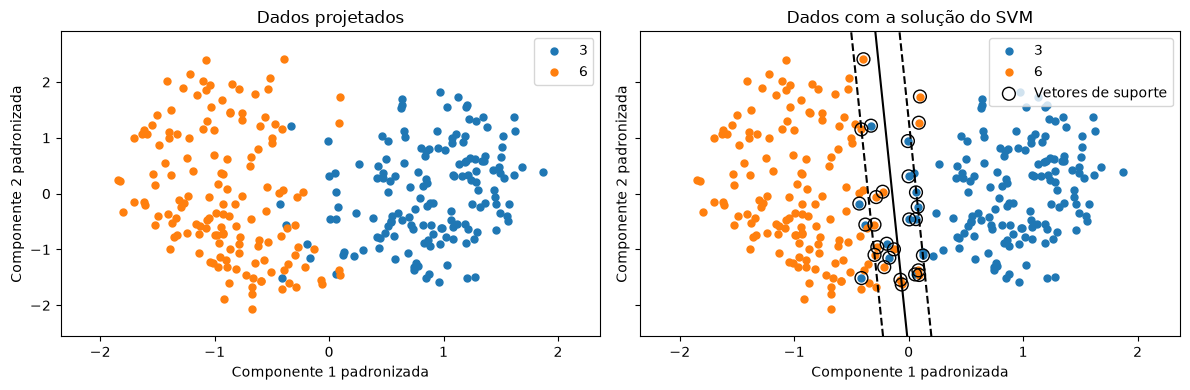

In [ ]:
plotar_svm(svm_rigido)

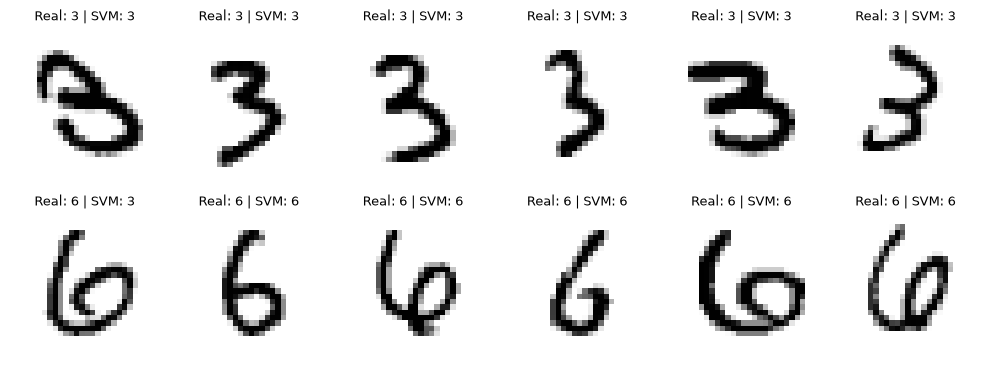

Previsto,3,6
Real,,
3,992,18
6,26,932


In [ ]:
mostrar_resultados(svm_rigido)

## Margem suave

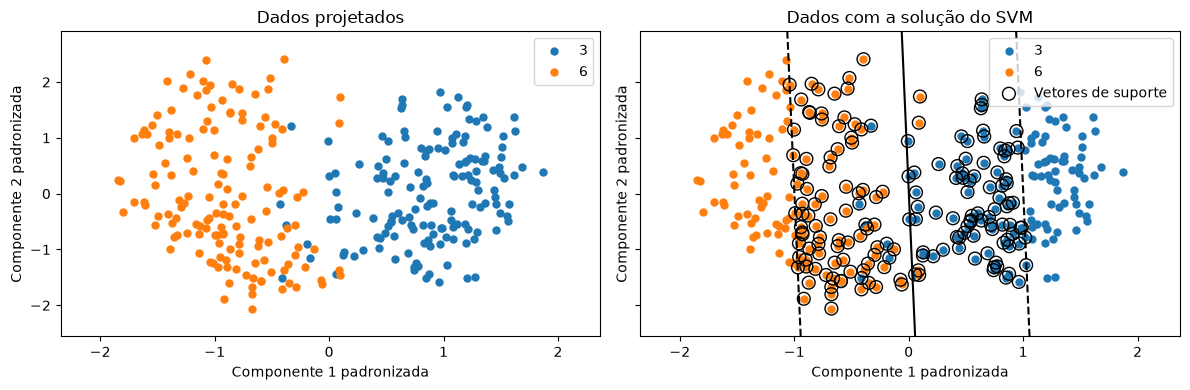

In [ ]:
plotar_svm(svm_suave)

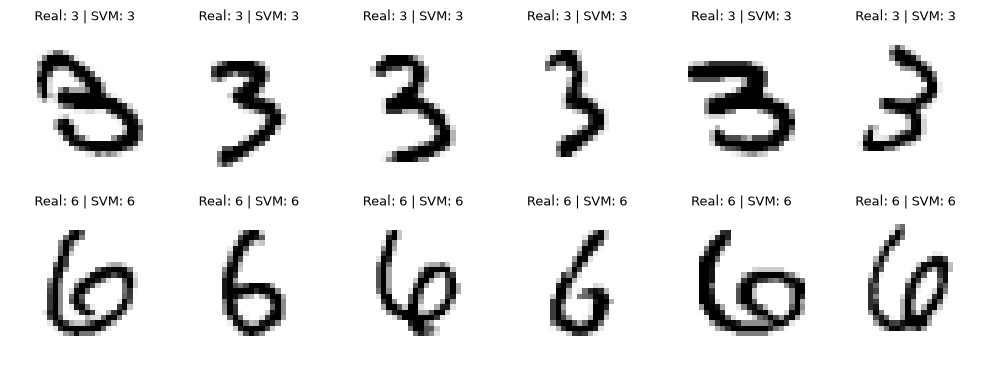

Previsto,3,6
Real,,
3,975,35
6,10,948


In [ ]:
mostrar_resultados(svm_suave)